# Validating an exposure engine: analytic EE, convergence and the PIT back-test

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 and 03 of this topic
- **Reading time:** about 60 minutes

**Question:** Is the simulated exposure of the 10-year swap internally correct, converged and consistent with its closed form, and does the Hull-White model that produces it survive a comparison with what the market actually delivered over 309 month ends?

## Objectives

By the end of this notebook you can:

- check a simulated exposure profile against the closed form of the swaption it must equal, and say why the check is a statement of the model and not of the market;
- check that the simulated short rate reprices discount bonds as martingales, and that the reported EEPE and CVA are the ones the profile implies;
- measure whether the exposure is converged in the number of paths in units of Monte Carlo error;
- run the probability-integral-transform back-test of the exposure forecast, with an Anderson-Darling statistic and critical values simulated under the model, and read why overlapping horizons need them;
- read the exceedance count of the PFE as a secondary test, and say what the red lights of the committed document mean.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.ccr import cva
from riskvalidation.ccr import exposure as ex
from riskvalidation.ccr import hw1f
from riskvalidation.ccr import swaps as sw
from riskvalidation.validation import ccr as vc
from scipy.stats import norm

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data is case C12 (counterparty credit risk), single-swap variant: the 10-year payer of 10 million USD of notebook 01 on the US Treasury par curve of 2025-09-30 (licence class `mirror-allowed`, synthetic trade, real market inputs). The document carries the 42 test rows the engine produced on it, and a **back-test** block: on each of 309 month ends from 2000-01 to 2025-09, the model is calibrated with data up to that date only, the swap is originated at par, 4,000 paths are simulated to six horizons (10 and 20 business days, 1, 3, 6 and 12 months) and the value of the book realised at the horizon, on the curve actually published then, is mapped to its PIT in the simulated sample.

- **Files read:** `data/derived/C12/single-swap.json` (the `tests` rows and the `backtest` block) and `data/derived/C12/netting-set.json` (curve, calibration and the four swaps, to rebuild the simulation).
- **What this notebook computes and what it reads:** the internal tests are computed here from the simulation, the PIT statistics from the committed PITs. The 309 back-test simulations of 4,000 paths are not rerun: they take minutes and the document commits their result.

The next cell loads both documents and counts the committed test rows by family and light.

In [2]:
# Load the two committed documents (three folders below the repository root) and count the committed test rows
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C12"
single = json.loads((derived / "single-swap.json").read_text(encoding="utf-8"))
netting = json.loads((derived / "netting-set.json").read_text(encoding="utf-8"))
out, base = single["outputs"], netting["outputs"]
bt = out["backtest"]
print("baked by riskvalidation", single["provenance"]["riskvalidation_version"], "| installed", rv.__version__)
LIGHT = {"green": "green", "red": "red", "amber": "amber"}

families = {}
for row in single["tests"]:
    key = row["test_id"].split(".")[1].split("_")[0]
    families.setdefault(key, {}).setdefault(LIGHT[row["light"]], 0)
    families[key][LIGHT[row["light"]]] += 1
for key, counts in families.items():
    print(f"  {key:15s}", counts)
print("window:", bt["window_start"], "to", bt["window_end"], "|", len(bt["dates"]), "dates")
print("paths per date:", bt["paths_per_date"])
print("PIT:", bt["pit_rule"], "|", bt["statistic"])

baked by riskvalidation 1.0.1 | installed 1.0.1
  ee              {'green': 1}
  martingale      {'green': 1}
  eepe            {'green': 1}
  cva             {'green': 1}
  path            {'green': 1}
  pit             {'red': 12}
  pfe             {'red': 18}
  quantlib        {'green': 4}
  reconcile       {'green': 1}
  ore             {'green': 2}
window: 2000-01 to 2025-09 | 309 dates
paths per date: 4000
PIT: (i + 1) / (N + 2) | Anderson-Darling W^2


## Method

### Step 1: the analytic EE against the simulated one

The expected exposure of a single swap has a closed form. The exposure of a payer swap at $t$ is the payoff of a payer swaption on the remaining swap, so in the risk-neutral measure $EE_B(t) = \mathrm{Swaption}(0; t) / P(0, t)$, with the swaption priced by the Jamshidian decomposition of the Hull-White model (a zero-coupon bond option at the rate $r^*$ that makes the coupon bond worth par). The identity holds on the reset dates of the swap, so the check is made there: 19 of the 33 report dates. The engine's `analytic_ee_single_swap` returns the profile and `ee_analytic_vs_simulated` compares it with the simulation: the statistic is the largest gap in units of Monte Carlo standard error, and the gate is 3 (a Contraste internal gate, not a regulatory threshold). We compare the discounted simulated EE with the analytic profile times $P(0,t)$. The next cell rebuilds the simulation of notebook 01 and runs the check.

In [3]:
# Rebuild the simulation of notebook 01 with the case's curve, calibration, seed and grid
tenors = np.array([p["tenor_years"] for p in base["curve"]["points"]])
zeros = np.array([p["zero_rate"] for p in base["curve"]["points"]])
a, sigma = base["calibration_used"]["a"], base["calibration_used"]["sigma"]
p0, forward = hw1f.curve_functions(zeros, tenors)
named = base["named_parameters"]
report = np.array(named["time_grid_years"]["value"])
main = np.concatenate([[0.0], report])
swaps = [
    sw.Swap(t["trade_id"], t["notional"]["amount"], t["fixed_rate"], t["side"] == "payer",
            t["start_years"], t["maturity_years"], t["fixed_frequency_per_year"])
    for t in base["book"]["trades"]
]
merged = np.unique(np.round(np.concatenate([main] + [main + d for d in (14 / 360, 28 / 360)]), 12))
grid = sw.simulation_grid(merged, swaps)
n_paths, seed = named["path_count"]["value"], named["seed"]["value"]
r = hw1f.simulate_short_rate(grid, a, sigma, forward, n_paths, seed)
numeraire = hw1f.bank_account(grid, r, a, sigma, p0, forward)
values = sw.swap_values_on_grid(swaps, grid, r, a, sigma, p0, forward)
ix = np.searchsorted(grid, report - sw.TIME_TOL)
p0r = p0(report)
v1, nm = values[0][:, ix], numeraire[:, ix]
ee_d, ee_d_se = ex.expected_exposure(v1, nm)
print("paths:", n_paths, "| seed:", seed, "| report dates:", report.size)

paths: 20000 | seed: 42 | report dates: 33


The next cell computes the closed-form EE of the first swap at its reset dates and compares it with the simulated one through the engine's test.

In [4]:
# The analytic EE of the single swap at its reset dates against the simulated EE
swap = swaps[0]
resets = sw.reset_times(swap)
pick = [k for k, t in enumerate(report) if np.min(np.abs(resets - t)) < 1e-9]
analytic = ex.analytic_ee_single_swap(swap, report[pick], a, sigma, p0, forward)
test1 = vc.ee_analytic_vs_simulated(analytic * p0r[pick], ee_d[pick], ee_d_se[pick], 3.0)
k1, k5 = np.searchsorted(report, [1.0 - 1e-9, 5.0 - 1e-9])
ee_fwd = ee_d / p0r

print("dates checked:", len(pick), "of", report.size)
print("statistic (largest gap in standard errors):", round(test1.statistic, 6))
print("largest absolute gap, USD:", round(test1.metric, 1), "| light:", LIGHT[test1.light.value])
print("analytic EE at 1 y and 5 y (forward measure):",
      np.round(analytic[[pick.index(k1), pick.index(k5)]], 0))
print("simulated EE at 1 y and 5 y:", np.round(ee_fwd[[k1, k5]], 0))

dates checked: 19 of 33
statistic (largest gap in standard errors): 0.89077
largest absolute gap, USD: 1161.3 | light: green
analytic EE at 1 y and 5 y (forward measure): [141685. 295711.]
simulated EE at 1 y and 5 y: [141414. 294524.]


The next cell draws the analytic EE at the reset dates over the simulated EE, with a band of three standard errors.

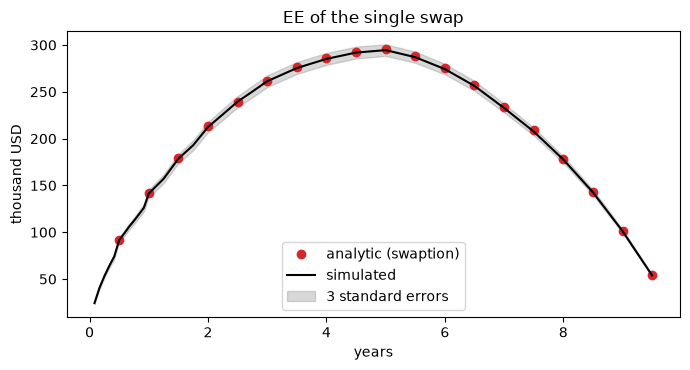

In [5]:
# Draw the analytic EE against the simulated one with a band of three standard errors
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(report[pick], analytic / 1e3, "o", color="tab:red", label="analytic (swaption)")
ax.plot(report, ee_fwd / 1e3, color="black", lw=1.5, label="simulated")
band = 3 * ee_d_se / p0r
ax.fill_between(report, (ee_fwd - band) / 1e3, (ee_fwd + band) / 1e3, color="grey", alpha=0.3,
                label="3 standard errors")
ax.set_xlabel("years")
ax.set_ylabel("thousand USD")
ax.set_title("EE of the single swap")
ax.legend()
fig.tight_layout()
plt.show()

The red dots, one per reset date, sit inside the grey band around the black simulated curve at every date, so the closed form and the simulation tell the same story and the largest gap is below one standard error. The agreement is a statement about the model: both numbers come from the Hull-White dynamics, so this check can catch an error in the code, in the discounting or in the paths, but it cannot say whether the Hull-White dynamics resemble the market. That second question is the back-test of Step 4.

### Step 2: martingales, and the reported numbers

Two more checks follow from the model and from the definitions.

- **Martingale test.** Because the model reprices today's curve, the discounted bond price $\exp(-\int_0^t r)\,P(t, T; r_t)$ has mean $P(0,T)$ for every $t \le T$. The engine's `martingale_discounted_bonds` compares the sample mean with $P(0,T)$ in standard errors. We take $T = 10$ years.
- **Recomputation.** `eepe_recomputed` rebuilds the effective EPE from the EE profile (running maximum, then the average over the first year) and compares it with the number reported; `cva_recomputed` rebuilds the CVA from the discounted EE and the default probabilities. Their gate is a relative difference of $10^{-9}$. A check that never fails tells nothing, so the cell also shows each of them going red when the reported number is wrong by 1%.

In [6]:
# The martingale test of the discounted bond price
keep = report <= 10.0 + 1e-9
means, ses = [], []
for k in np.where(keep)[0]:
    i = ix[k]
    bond = hw1f.bond_price(r[:, i], float(grid[i]), 10.0, a, sigma, p0, forward) / numeraire[:, i]
    means.append(bond.mean())
    ses.append(bond.std(ddof=1) / np.sqrt(bond.size))
p_top = float(p0(np.array(10.0)))
test2 = vc.martingale_discounted_bonds(np.array(means), np.full(len(means), p_top), np.array(ses), 3.0)
mean_5 = means[int(np.searchsorted(report, 5.0 - 1e-9))]
print("P(0,10) =", round(p_top, 6), "| mean of the discounted bond at 5 y:", round(mean_5, 6))
print("martingale statistic:", round(test2.statistic, 6),
      "| largest absolute gap:", f"{test2.metric:.2e}", "|", LIGHT[test2.light.value])

P(0,10) = 0.658648 | mean of the discounted bond at 5 y: 0.65861
martingale statistic: 0.164091 | largest absolute gap: 6.96e-05 | green


The next cell runs the recomputation tests on the reported EEPE and CVA, each once as reported and once with the reported number 1% too high.

In [7]:
# The EEPE and CVA recomputation tests, as reported and with a 1% error to see them fail
ee_f = np.array(out["exposure"]["ee"]["values"])
eepe_reported = out["exposure"]["eepe"]["amount"]
cv = out["cva_dva"]
survival = np.array([b["survival"] for b in cv["buckets"]])
pd_cp = cva.default_probabilities(np.concatenate([[1.0], survival]))
epe_d = np.array(out["exposure"]["ee_discounted"]["values"])
labels = ("as reported", 1.0), ("reported 1% too high", 1.01)
for label, factor in labels:
    t3 = vc.eepe_recomputed(report, ee_f, eepe_reported * factor)
    print(f"EEPE {label:26s} relative difference {t3.metric:.2e} | {LIGHT[t3.light.value]}")
for label, factor in labels:
    t4 = vc.cva_recomputed(epe_d, pd_cp, cv["lgd"], cv["cva"]["amount"] * factor)
    print(f"CVA  {label:26s} relative difference {t4.metric:.2e} | {LIGHT[t4.light.value]}")

EEPE as reported                relative difference 0.00e+00 | green
EEPE reported 1% too high       relative difference 1.00e-02 | red
CVA  as reported                relative difference 0.00e+00 | green
CVA  reported 1% too high       relative difference 1.00e-02 | red


### Step 3: convergence in the number of paths

Monte Carlo error falls like $1/\sqrt{P}$, so a profile is converged when doubling the paths moves it by less than its own error. The engine's `path_convergence` takes the EE profile and the CVA at two path counts, with the standard error of the smaller count, and reports the largest change in units of that error; the gate is $k_{se}=3$ for green and $2k_{se}$ for amber. An older version used a unit band on the coefficient of variation, which lit on noise: the EE of an at-the-money swap has a coefficient of variation above 1. To keep the antithetic pairs, the smaller sample takes the first quarter of the paths and their mirrors. The next cell builds the two samples (10,000 and 20,000 paths) and runs the test.

In [8]:
# EE and CVA at 5,000, 10,000 and 20,000 paths (keeping the antithetic pairs) and the convergence test
half = n_paths // 2
dt = np.diff(np.concatenate([[0.0], report]))
x_pos = np.maximum(v1, 0.0)
ee_by, ee_se_by, cva_by, cva_se_by = {}, {}, {}, {}
for m in (n_paths // 4, n_paths // 2, n_paths):
    idx = np.concatenate([np.arange(m // 2), half + np.arange(m // 2)])
    e_d, e_se = ex.expected_exposure(x_pos[idx], nm[idx])
    ee_by[m], ee_se_by[m] = e_d / p0r, e_se / p0r
    discounted = x_pos[idx] / nm[idx]
    cva_by[m], cva_se_by[m] = cva.wwr_cva(np.zeros((m, report.size)), discounted, survival, dt, cv["lgd"], 0.0)
test5 = vc.path_convergence(ee_by, cva_by, ee_se_by_path_count=ee_se_by, cva_se_by_path_count=cva_se_by, k_se=3.0)
for m in ee_by:
    eepe_m = ex.effective_epe(report, ex.effective_ee(ee_by[m]))
    print(f"{m:6d} paths: EEPE {eepe_m:10.1f} | CVA {cva_by[m]:9.2f} +/- {cva_se_by[m]:6.2f}")
thr = test5.extras["thresholds"]
print("compared counts:", thr["smaller_count"], "and", thr["larger_count"])
print("largest EE change in standard errors:", round(test5.statistic, 6))
print("CVA change in standard errors:", round(test5.metric, 6), "| light:", LIGHT[test5.light.value])

  5000 paths: EEPE    86021.1 | CVA  10332.46 +/- 110.95
 10000 paths: EEPE    87117.1 | CVA  10352.49 +/-  79.35
 20000 paths: EEPE    87550.9 | CVA  10337.65 +/-  55.84
compared counts: 10000 and 20000
largest EE change in standard errors: 0.789312
CVA change in standard errors: 0.186955 | light: green


### Step 4: the PIT back-test

The tests so far check the model against itself. A back-test checks it against the market. On each date $d$ the model gives a distribution of the value of the book at a horizon $h$; the market then delivers one realised value $v_d$. If the model is right, the probability integral transform

$$\mathrm{PIT}_d = \frac{i_d + 1}{N + 2}, \qquad i_d = \#\{\text{simulated values below } v_d\}$$

is uniform on $(0,1)$ across dates (BCBS 185, paragraph 25; the $(i+1)/(N+2)$ rule avoids the values 0 and 1). The uniformity is measured by the Anderson-Darling statistic

$$W^2 = -n - \sum_{k=1}^n \frac{2k-1}{n}\,\big[\ln x_k + \ln(1 - x_{n+1-k})\big]$$

which weighs the tails heavily, where exposure models fail. The critical values of $W^2$ for independent uniform PITs are tabulated (2.492 at 5%), but month-end dates with horizons of 3, 6 and 12 months **overlap**, so the PITs are dependent and the independent table is too lenient. The engine therefore asks for critical values simulated under the model itself, with the same dates and the same overlaps (`simulate_pit_critical_values`), and reports the independent values beside them, never in their place, together with an effective sample size. The next cell computes $W^2$ and the effective sample size from the committed PITs of the six horizons and sets them beside the two critical values.

In [9]:
# W^2 and the effective sample size of the committed PITs of the six horizons, beside the critical values
horizons = bt["book_horizons"]
w2s, crits = [], []
print(f"{'horizon':>10s}{'n':>5s}{'W2':>10s}{'ESS':>8s}{'iid 5%':>9s}{'simulated 5%':>16s}  reject")
for h in horizons:
    pits = np.array(h["pits"])
    w2, ess = vc.anderson_darling_w2(pits), vc.effective_sample_size(pits)
    crit = h["critical_simulated"]["p05"]
    w2s.append(w2)
    crits.append(crit)
    verdict = "yes" if w2 > crit else "no"
    print(f"{h['horizon']:>10s}{h['n']:5d}{w2:10.3f}{ess:8.1f}{h['critical_iid']['p05']:9.3f}{crit:16.3f}  {verdict}")

pits10 = np.array(horizons[0]["pits"])
above = [round(float((pits10 > q).mean()), 3) for q in (0.90, 0.95, 0.99)]
below = [round(float((pits10 < q).mean()), 3) for q in (0.10, 0.05, 0.01)]
print("share of PITs above the 90, 95 and 99 percent levels at the 10-day horizon (uniform: 10%, 5%, 1%):", above)
print("share of PITs below the 10, 5 and 1 percent levels:", below)
rate_w2 = vc.anderson_darling_w2(np.array(bt["risk_factor"]["horizons"][0]["pits"]))
print("the 3-month rate itself, W2 at the 10-day horizon:", round(rate_w2, 3))

   horizon    n        W2     ESS   iid 5%    simulated 5%  reject
      10bd  309   107.678   309.0    2.492           2.391  yes
      20bd  309    90.995   309.0    2.492           2.728  yes
        1m  309    89.772   309.0    2.492           2.539  yes
        3m  309    97.569   134.8    2.492           6.581  yes
        6m  309    95.896    76.5    2.492          11.813  yes
       12m  309   153.093    54.8    2.492          24.053  yes
share of PITs above the 90, 95 and 99 percent levels at the 10-day horizon (uniform: 10%, 5%, 1%): [0.314, 0.272, 0.188]
share of PITs below the 10, 5 and 1 percent levels: [0.288, 0.227, 0.159]
the 3-month rate itself, W2 at the 10-day horizon: 34.769


The next cell draws the histogram of the 10-day PITs against the uniform density, and $W^2$ of each horizon against its simulated 5% critical value.

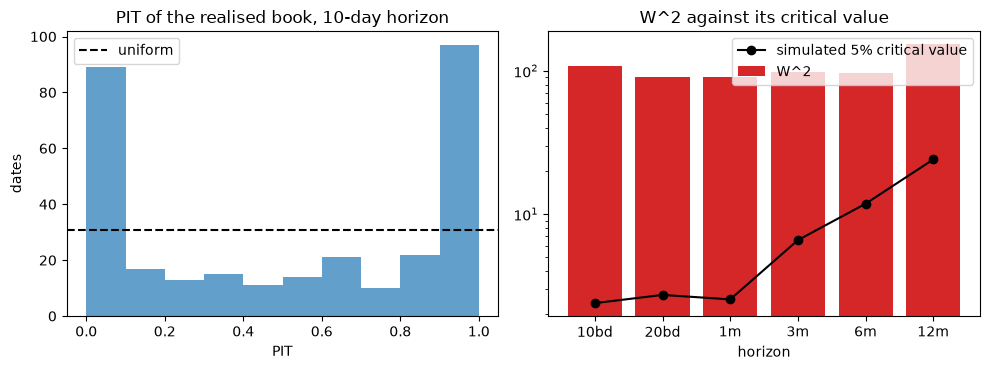

In [10]:
# Draw the histogram of the 10-day PITs (left) and W^2 against the simulated 5% critical value by horizon (right)
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8))
left.hist(pits10, bins=10, range=(0, 1), color="tab:blue", alpha=0.7)
left.axhline(len(pits10) / 10, color="black", ls="--", label="uniform")
left.set_xlabel("PIT")
left.set_ylabel("dates")
left.set_title("PIT of the realised book, 10-day horizon")
left.legend()
x = np.arange(len(horizons))
right.bar(x, w2s, color="tab:red", label="W^2")
right.plot(x, crits, "ko-", label="simulated 5% critical value")
right.set_xticks(x, [h["horizon"] for h in horizons])
right.set_yscale("log")
right.set_xlabel("horizon")
right.set_title("W^2 against its critical value")
right.legend()
fig.tight_layout()
plt.show()

On the left, a correct model would give a flat histogram near the dashed line; here the last bin is several times too high and the first one too, so realised outcomes fall in both tails far more often than the model says. On the right, every red bar stands far above the black marker, so the rejection does not depend on the critical value used: the largest critical value, that of the 12-month horizon, is still several times smaller than its statistic. The log scale hides how large the gap is. The charts reject this model on this book and period; they do not say what a better model would be.

### Step 5: where the critical values come from

The engine's `simulate_pit_critical_values` takes a function that draws the PITs of one whole back-test under the model, and returns the 95th and 99th percentiles of $W^2$ over many such back-tests. The case's sampler uses the exact dates, the mean reversion of each date and the real overlap of the horizons (it takes minutes at 1,000 back-tests). To see the mechanism at small cost, the next cell runs the engine's function with two toy samplers on 309 dates: independent PITs, which must give the tabulated 2.49, and PITs of a window of 3 overlapping months, which give a larger critical value because dependence makes extreme $W^2$ more common. These two samplers are an illustration and not the case's; the case's values are in the committed document.

In [11]:
# The engine's critical-value simulation with two toy samplers on 309 dates: independent and 3-date overlap
n_dates = len(bt["dates"])


def draw_independent(rng):
    # Independent uniform PITs: the case the tabulated critical values describe
    return (rng.integers(0, 4000, n_dates) + 1.0) / 4002.0


def draw_overlapping(rng):
    # Each PIT is the normal CDF of the mean of 3 consecutive increments
    z = np.convolve(rng.standard_normal(n_dates + 2), np.ones(3), "valid") / np.sqrt(3.0)
    return (rng.binomial(4000, norm.cdf(z)) + 1.0) / 4002.0


toy = {}
for label, sampler in (("independent", draw_independent), ("3-date overlap", draw_overlapping)):
    crit = vc.simulate_pit_critical_values(sampler, 1000, 7)
    toy[label] = crit.p05
    print(f"{label:22s} p05 = {crit.p05:7.3f} | p01 = {crit.p01:7.3f} | ESS = {crit.effective_sample_size:6.1f}")
print("tabulated independent values:", vc.IID_CRITICAL_VALUES[0.05], vc.IID_CRITICAL_VALUES[0.01])

independent            p05 =   2.503 | p01 =   3.491 | ESS =  309.0
3-date overlap         p05 =   6.393 | p01 =  10.030 | ESS =  110.4
tabulated independent values: 2.492 3.88


The next cell draws the 5% critical value of the two toy samplers beside the tabulated independent value and the values the case simulated for its six horizons.

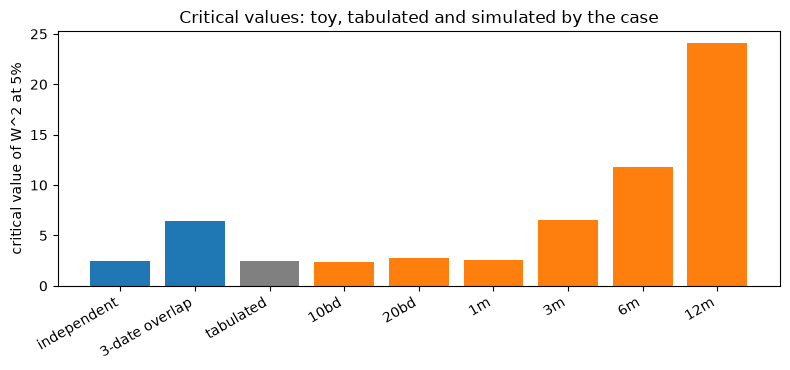

In [12]:
# Draw the 5% critical value of the toy samplers, the tabulated value and the case's six horizons
names = list(toy) + ["tabulated"] + [h["horizon"] for h in horizons]
heights = list(toy.values()) + [vc.IID_CRITICAL_VALUES[0.05]] + crits
colors = ["tab:blue"] * 2 + ["grey"] + ["tab:orange"] * len(horizons)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(range(len(names)), heights, color=colors)
ax.set_xticks(range(len(names)), names, rotation=30, ha="right")
ax.set_ylabel("critical value of W^2 at 5%")
ax.set_title("Critical values: toy, tabulated and simulated by the case")
fig.tight_layout()
plt.show()

The first bar, independent PITs, lands on the tabulated value of 2.49, which shows that the simulation machinery reproduces a known answer. The second bar, a three-date overlap, is already more than twice as high. The orange bars are the case's own values: they stay near the tabulated one for the horizons up to one month and climb for 3, 6 and 12 months, in step with the loss of effective sample size. The toy bars illustrate the direction of the effect and are not a calibration of it.

### Step 6: the exceedance count, a secondary row

The older way to back-test an exposure is to count how often the realised value exceeds the PFE forecast. The Kupiec likelihood-ratio test compares the exception count $x$ among $n$ dates with the expected rate $1 - q$; it depends on $x$ and $n$ only. BCBS 185 (paragraph 27) warns that such criteria assume independent exceptions and that overlapping data break that, so the engine carries the caveat in the row and Contraste marks the row secondary. Since the test depends only on the count, we can rebuild a row from the committed exceedance counts, using arrays that have exactly $x$ exceptions. The next cell does it for the 10-day horizon, then prints the W² of the three sub-windows of the book.

In [13]:
# The Kupiec rows of the 10-day horizon rebuilt from the exceedance counts, and W^2 by sub-window
h10 = horizons[0]
print(f"{'q':>5s}{'x':>5s}{'expected':>10s}{'LR':>10s}{'p-value':>12s}{'light':>8s}")
for e in h10["exceedances"]:
    n, x, q = h10["n"], e["count"], e["quantile"]
    t6 = vc.pfe_exceedance_backtest(np.concatenate([np.ones(x), np.zeros(n - x)]), np.full(n, 0.5), q)
    print(f"{q:5.2f}{x:5d}{e['expected']:10.1f}{t6.statistic:10.3f}{t6.p_value:12.2e}{LIGHT[t6.light.value]:>8s}")
caveat = "yes" if "paragraph 27" in t6.extras["caveat"] else "no"
print("the row carries the BCBS 185 paragraph 27 caveat:", caveat)
first = bt["sub_windows"][0]["results"]
print(f"{'sub-window':14s}" + "".join(f"{res['horizon']:>9s}" for res in first))
for w in bt["sub_windows"]:
    cells = "".join(f"{res['w2']:9.1f}" for res in w["results"])
    print(f"{w['window']:14s}" + cells, f"  (n = {w['results'][0]['n']})")

    q    x  expected        LR     p-value   light
 0.90   97      30.9   106.856    4.79e-25     red
 0.95   84      15.5   164.782    1.02e-37     red
 0.99   58       3.1   240.829    2.59e-54     red
the row carries the BCBS 185 paragraph 27 caveat: yes
sub-window         10bd     20bd       1m       3m       6m      12m
before-2008        77.1     75.8     71.4     74.8     69.9    118.4   (n = 96)
2008-2019          21.1     14.6     19.4     30.4     52.7    111.0   (n = 144)
from-2020          29.8     24.7     20.3     24.0     23.6     44.8   (n = 69)


## Results

**Answer:** The engine is internally correct and the model fails the market. The analytic EE agrees with the simulation within 0.89 Monte Carlo standard errors (gate 3), the EEPE and CVA recomputations turn red when the reported number is 1% too high, and doubling the paths from 10,000 to 20,000 moves the EE by 0.79 standard errors. Yet the back-test gives $W^2$ of 107.7 at 10 days and 153.1 at 12 months, against simulated 5% critical values of 2.39 and 24.05, and at the 10-day horizon 31.4% of the PITs lie above 0.90 where 10% are expected.

- **The document at a glance.** Of the 42 committed rows of the single-swap variant, the five internal checks (analytic EE, martingale, EEPE and CVA recomputation, path convergence) are green, the four QuantLib comparisons and the three ORE rows are green (notebook 07), and the 30 rows of the back-test are red: 12 PIT rows and 18 exceedance rows.
- **Analytic EE.** At the 19 reset dates the largest absolute gap is 1,161 USD. At one year the analytic EE is 141,685 and the simulated one 141,414; at five years 295,711 and 294,524, a difference of 0.4%.
- **Martingale.** The mean of the discounted 10-year bond is 0.65861 at five years against $P(0,10) = 0.658648$; the largest standardised gap is 0.16 and the largest absolute gap 7e-5.
- **Recomputation.** The EEPE and the CVA of the document equal the ones recomputed from the profile (relative difference 0). Reported 1% too high, each test returns a relative difference of 1e-2 and a red light, so the gate of 1e-9 does discriminate.
- **Convergence.** EEPE is 86,021, 87,117 and 87,551 at 5,000, 10,000 and 20,000 paths, and the CVA 10,332 (+/- 111), 10,352 (+/- 79) and 10,338 (+/- 56). The change from 10,000 to 20,000 paths is 0.79 standard errors of the profile and 0.19 of the CVA: green.
- **The back-test rejects the model at every horizon.** $W^2$ is 107.7, 91.0, 89.8, 97.6, 95.9 and 153.1 from 10 days to 12 months, against simulated 5% critical values of 2.39, 2.73, 2.54, 6.58, 11.81 and 24.05. The independent table (2.492) would be the wrong yardstick for 3 months and beyond: the effective sample size falls from 309 to 134.8, 76.5 and 54.8 as the horizons overlap, and the simulated critical value rises with it. The same test on the 3-month rate itself gives 34.8 at 10 days, so the rate dynamics are rejected too.
- **Where it fails.** At the 10-day horizon 31.4% of the PITs are above 0.90 and 18.8% above 0.99 (a uniform PIT gives 10% and 1%), and 28.8% are below 0.10: the model is too narrow. The Kupiec rows agree: 97 exceptions of the 90% PFE in 309 dates against 30.9 expected, 84 against 15.5 at 95% and 58 against 3.1 at 99%. The caveat of BCBS 185 holds for these rows: the counts assume independence.
- **Reading the toy samplers.** Independent PITs give a simulated 5% value of 2.50, the tabulated 2.49; PITs of a three-date overlapping window give 6.39 with an effective sample size of 110.

What this notebook does not show: the case's own sampler of the critical values (committed, not rerun), the comparison with ORE and QuantLib (notebook 07), or a repair of the model: recalibrating on a window or changing the model class is a modelling decision outside this validation.

## Summary

- A model of exposure is checked three ways: against its closed form (analytic EE), against its own identities (martingale, recomputation) and against itself with more paths (convergence); each has a gate in Monte Carlo standard errors or a relative tolerance, and a gate that cannot fail is useless, so the notebook makes two of them fail.
- The market back-test maps each realised value to a PIT in the simulated distribution and measures uniformity with Anderson-Darling $W^2$; overlapping horizons make the PITs dependent, so the critical values are simulated under the model and the independent table is shown only beside them.
- The committed Hull-White model passes every internal check and fails every back-test: it is rejected at all six horizons, at 10 days the realised outcomes fall in the tails three to nineteen times more often than expected, and $W^2$ stays large in every sub-window.
- Kupiec counts agree with the PIT test and carry the BCBS 185 caveat about dependence.

**What to try next.** Replace the 0.5 of the exceedance arrays by other forecasts and watch the Kupiec statistic depend on the count alone; change the window length of the overlapping sampler to 6 and compare its 5% value with the committed 6-month one. Then continue with notebook 07.

## References

- BCBS (2010), Sound practices for backtesting counterparty credit risk models, publication 185. https://www.bis.org/publ/bcbs185.htm
- Formenti, L., Spadafora, L., Terraneo, F. and Ramponi, A., Probability integral transform and Anderson-Darling backtests, arXiv 1505.04593. https://arxiv.org/abs/1505.04593
- BCBS, Basel Framework, CRE53 Internal model method for counterparty credit risk (in force 2023-01-01, published 2020-06-05). https://www.bis.org/basel_framework/chapter/CRE/53.htm?inforce=20230101&published=20200605
- Hull, J. and White, A. (2012), CVA and wrong way risk, Financial Analysts Journal 68(5), 58-69. https://doi.org/10.2469/faj.v68.n5.6